Found 10 parquet files:
  CanESM5-FUT/year_2080/month_08.parquet
  CanESM5-HIST/year_1998/month_08.parquet
  HadGEM3-GC31-MM-FUT/year_2080/month_08.parquet
  HadGEM3-GC31-MM-HIST/year_1998/month_08.parquet
  MPI-ESM1-2-LR-FUT/year_2080/month_08.parquet
  MPI-ESM1-2-LR-HIST/year_1998/month_08.parquet
  MRI-ESM2-0-FUT/year_2080/month_08.parquet
  MRI-ESM2-0-HIST/year_1998/month_08.parquet
  TaiESM1-FUT/year_2080/month_08.parquet
  TaiESM1-HIST/year_1998/month_08.parquet

Total storm snapshots: 144,098


,,storms,area_median,area_p95,tmin_median,pmax_median,rain_p99_median,complexity_median,aspect_median
run,year,,,,,,,,
CanESM5-FUT,2080,10437,22967.3,203141.9,-64.7,38.1,33.1,0.2,1.6
CanESM5-HIST,1998,17294,18865.9,148626.3,-62.6,28.2,26.2,0.2,1.5
HadGEM3-GC31-MM-FUT,2080,11643,24394.3,200215.0,-67.2,26.3,23.2,0.2,1.6
HadGEM3-GC31-MM-HIST,1998,20244,19066.6,175383.9,-65.8,22.4,20.7,0.2,1.6
MPI-ESM1-2-LR-FUT,2080,15454,22565.9,178540.4,-63.6,22.5,18.7,0.2,1.7
MPI-ESM1-2-LR-HIST,1998,19255,21073.3,178843.1,-63.9,21.5,19.4,0.2,1.6
MRI-ESM2-0-FUT,2080,8709,24036.5,221889.2,-69.2,23.8,20.9,0.2,1.5
MRI-ESM2-0-HIST,1998,13775,19916.4,187030.1,-66.0,22.5,20.3,0.2,1.6
TaiESM1-FUT,2080,10766,27022.1,226463.5,-70.7,25.8,21.6,0.2,1.6



Quality checks:
Area < 5000 km²:         0
Area > 300000 km²:       0
Tmin > -50°C:            0
Missing shape metrics:   260
Shape complexity > 0.5:  2172
Aspect ratio > 5:        2535

18 UTC storm snapshots: 8,371


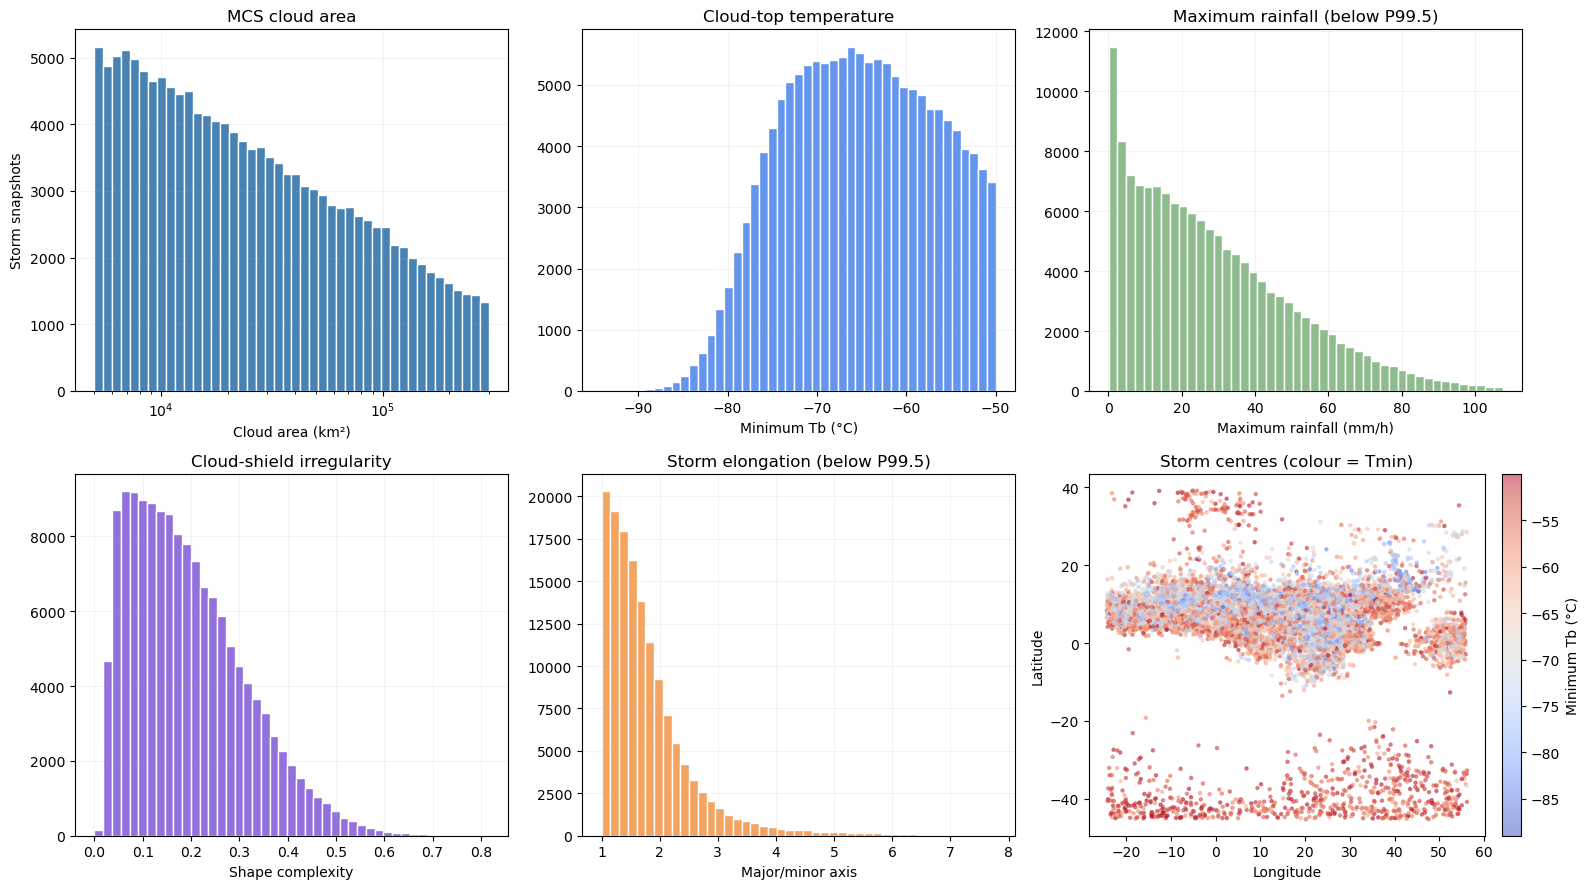

In [2]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------
# SETTINGS
# -------------------------------------------------------
ROOT = Path("/gws/ssde/j25b/cocoon/MCS_5000km2_tables_v3/"
            "CP4_base_tables_tir-prcp")

MONTH = 8
RUN = None                  # e.g. "CanESM5-HIST", or None for all runs
SMOKE_TEST = False          # True for --max-hours test outputs

# -------------------------------------------------------
# LOAD AVAILABLE PARQUETS
# -------------------------------------------------------
if SMOKE_TEST:
    files = sorted((ROOT / "_smoke_tests").glob(
        f"*/year_*/month_{MONTH:02d}_first_*h.parquet"))
else:
    files = sorted(ROOT.glob(f"*/year_*/month_{MONTH:02d}.parquet"))

if RUN is not None:
    files = [f for f in files if f.parent.parent.name == RUN]

if not files:
    raise FileNotFoundError(
        "No completed Parquets found. Try SMOKE_TEST=True "
        "if only the 24-hour test has finished."
    )

print(f"Found {len(files)} parquet files:")
for f in files:
    print(" ", f.relative_to(ROOT))

mcs = pd.concat(
    [pd.read_parquet(f) for f in files],
    ignore_index=True
)

print(f"\nTotal storm snapshots: {len(mcs):,}")

# -------------------------------------------------------
# QUICK SUMMARY BY MODEL AND YEAR
# -------------------------------------------------------
summary = (
    mcs.groupby(["run", "year"])
    .agg(
        storms=("area", "size"),
        area_median=("area", "median"),
        area_p95=("area", lambda x: x.quantile(0.95)),
        tmin_median=("tmin", "median"),
        pmax_median=("precipitation_max", "median"),
        rain_p99_median=("precipitation_p99", "median"),
        complexity_median=("shape_complexity", "median"),
        aspect_median=("aspect_ratio", "median"),
    )
    .round(1)
)

display(summary)

print("\nQuality checks:")
print("Area < 5000 km²:        ", (mcs.area < 5000).sum())
print("Area > 300000 km²:      ", (mcs.area > 300000).sum())
print("Tmin > -50°C:           ", (mcs.tmin > -50).sum())
print("Missing shape metrics:  ", mcs.shape_complexity.isna().sum())
print("Shape complexity > 0.5: ", (mcs.shape_complexity > 0.5).sum())
print("Aspect ratio > 5:       ", (mcs.aspect_ratio > 5).sum())

mcs18 = mcs[np.isclose(mcs.storm_hour_end_utc, 18)]
print(f"\n18 UTC storm snapshots: {len(mcs18):,}")

# -------------------------------------------------------
# DIAGNOSTIC DISTRIBUTIONS
# -------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

# 1. Cloud area
x = mcs["area"].dropna()
axes[0].hist(x, bins=np.geomspace(5000, 300000, 45),
             color="steelblue", edgecolor="white")
axes[0].set_xscale("log")
axes[0].set_xlabel("Cloud area (km²)")
axes[0].set_ylabel("Storm snapshots")
axes[0].set_title("MCS cloud area")

# 2. Minimum cloud-top temperature
axes[1].hist(mcs["tmin"].dropna(), bins=45,
             color="cornflowerblue", edgecolor="white")
axes[1].set_xlabel("Minimum Tb (°C)")
axes[1].set_title("Cloud-top temperature")

# 3. Maximum rainfall
x = mcs["precipitation_max"].dropna()
axes[2].hist(x[x <= x.quantile(0.995)], bins=45,
             color="darkseagreen", edgecolor="white")
axes[2].set_xlabel("Maximum rainfall (mm/h)")
axes[2].set_title("Maximum rainfall (below P99.5)")

# 4. Shape complexity
axes[3].hist(mcs["shape_complexity"].dropna(), bins=45,
             color="mediumpurple", edgecolor="white")
axes[3].set_xlabel("Shape complexity")
axes[3].set_title("Cloud-shield irregularity")

# 5. Aspect ratio
x = mcs["aspect_ratio"].dropna()
axes[4].hist(x[x <= x.quantile(0.995)], bins=45,
             color="sandybrown", edgecolor="white")
axes[4].set_xlabel("Major/minor axis")
axes[4].set_title("Storm elongation (below P99.5)")

# 6. Geographical distribution
sample = mcs.sample(min(len(mcs), 10000), random_state=42)
sc = axes[5].scatter(
    sample["clon"], sample["clat"],
    c=sample["tmin"], cmap="coolwarm",
    s=5, alpha=0.5, rasterized=True
)
axes[5].set_xlabel("Longitude")
axes[5].set_ylabel("Latitude")
axes[5].set_title("Storm centres (colour = Tmin)")
fig.colorbar(sc, ax=axes[5], label="Minimum Tb (°C)",
             fraction=0.046, pad=0.04)

for ax in axes[:5]:
    ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


African OBS regions: ['WAf', 'SAf', 'CAf', 'EAf']
Region boxes: {'WAf': [-18, 25, 4, 25], 'SAf': [17, 33, -32, -14], 'CAf': [13.5, 29, -14, 4], 'EAf': [29, 44, -2.5, 15.5]}
OBS: 320,446 storm snapshots (0 overlap duplicates removed)
CP4 before regional filtering: 144,098
CP4 inside OBS Africa boxes: 93,267

TEMPORAL COVERAGE OF DATA USED IN THE PLOTS


,Months,Years,N years,Unique UTC hours,N hours,Storm snapshots
Dataset,,,,,,
OBS,08,2000–2020,21,"00, 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11...",24,320446
CanESM5-FUT,08,2080–2080,1,"00, 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11...",24,6280
CanESM5-HIST,08,1998–1998,1,"00, 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11...",24,11338
HadGEM3-GC31-MM-FUT,08,2080–2080,1,"00, 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11...",24,6301
HadGEM3-GC31-MM-HIST,08,1998–1998,1,"00, 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11...",24,13328
MPI-ESM1-2-LR-FUT,08,2080–2080,1,"00, 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11...",24,9500
MPI-ESM1-2-LR-HIST,08,1998–1998,1,"00, 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11...",24,13558
MRI-ESM2-0-FUT,08,2080–2080,1,"00, 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11...",24,5999
MRI-ESM2-0-HIST,08,1998–1998,1,"00, 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11...",24,9645


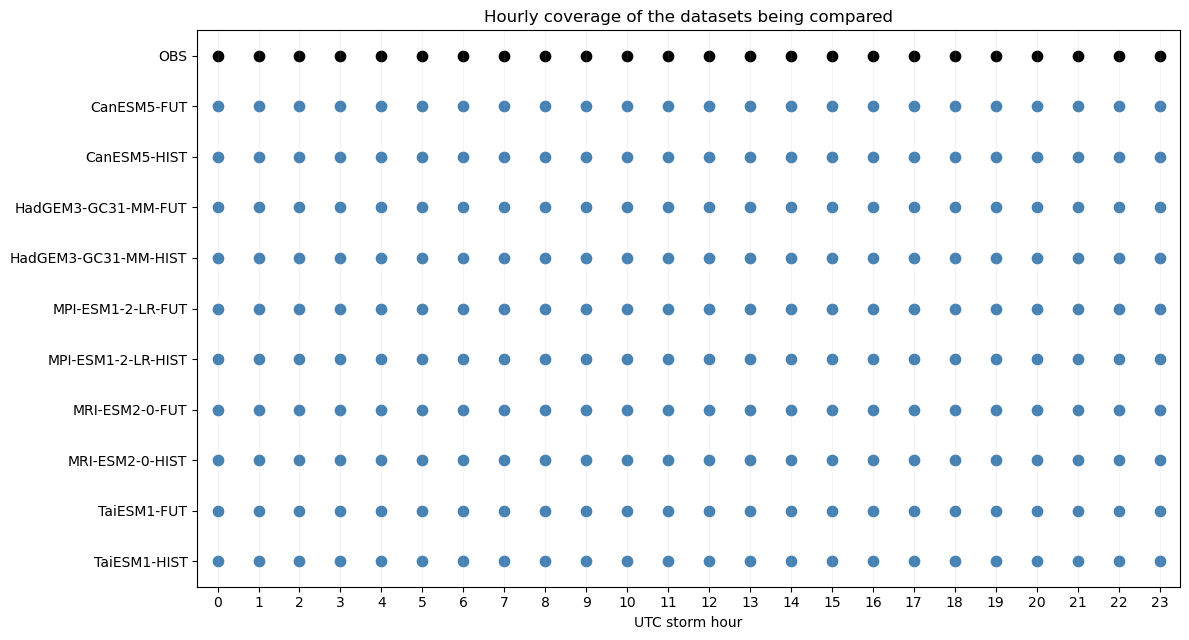

,n,area_median,area_p95,tmin_median,pmax_median,rain_p99_median,complexity_median,aspect_median,snapshots_per_day
dataset,,,,,,,,,
CanESM5-FUT,6280,24039.26,195567.94,-66.74,37.06,32.74,0.14,1.50,202.58
CanESM5-HIST,11338,18564.14,143471.42,-64.02,25.82,24.31,0.16,1.49,365.74
HadGEM3-GC31-MM-FUT,6301,24488.83,194534.50,-69.88,28.24,25.21,0.15,1.50,210.03
HadGEM3-GC31-MM-HIST,13328,17903.03,153534.57,-66.81,21.02,19.87,0.17,1.55,444.27
MPI-ESM1-2-LR-FUT,9500,22314.01,181026.80,-65.14,25.20,21.01,0.17,1.66,306.45
MPI-ESM1-2-LR-HIST,13558,19845.69,163064.92,-65.54,21.19,19.37,0.17,1.55,437.35
MRI-ESM2-0-FUT,5999,22547.34,203084.46,-70.78,24.49,22.00,0.14,1.50,193.52
MRI-ESM2-0-HIST,9645,19105.07,177426.82,-67.60,22.78,20.77,0.15,1.49,311.13
OBS,320446,17094.38,146926.77,-67.38,9.39,7.61,0.19,1.63,492.24


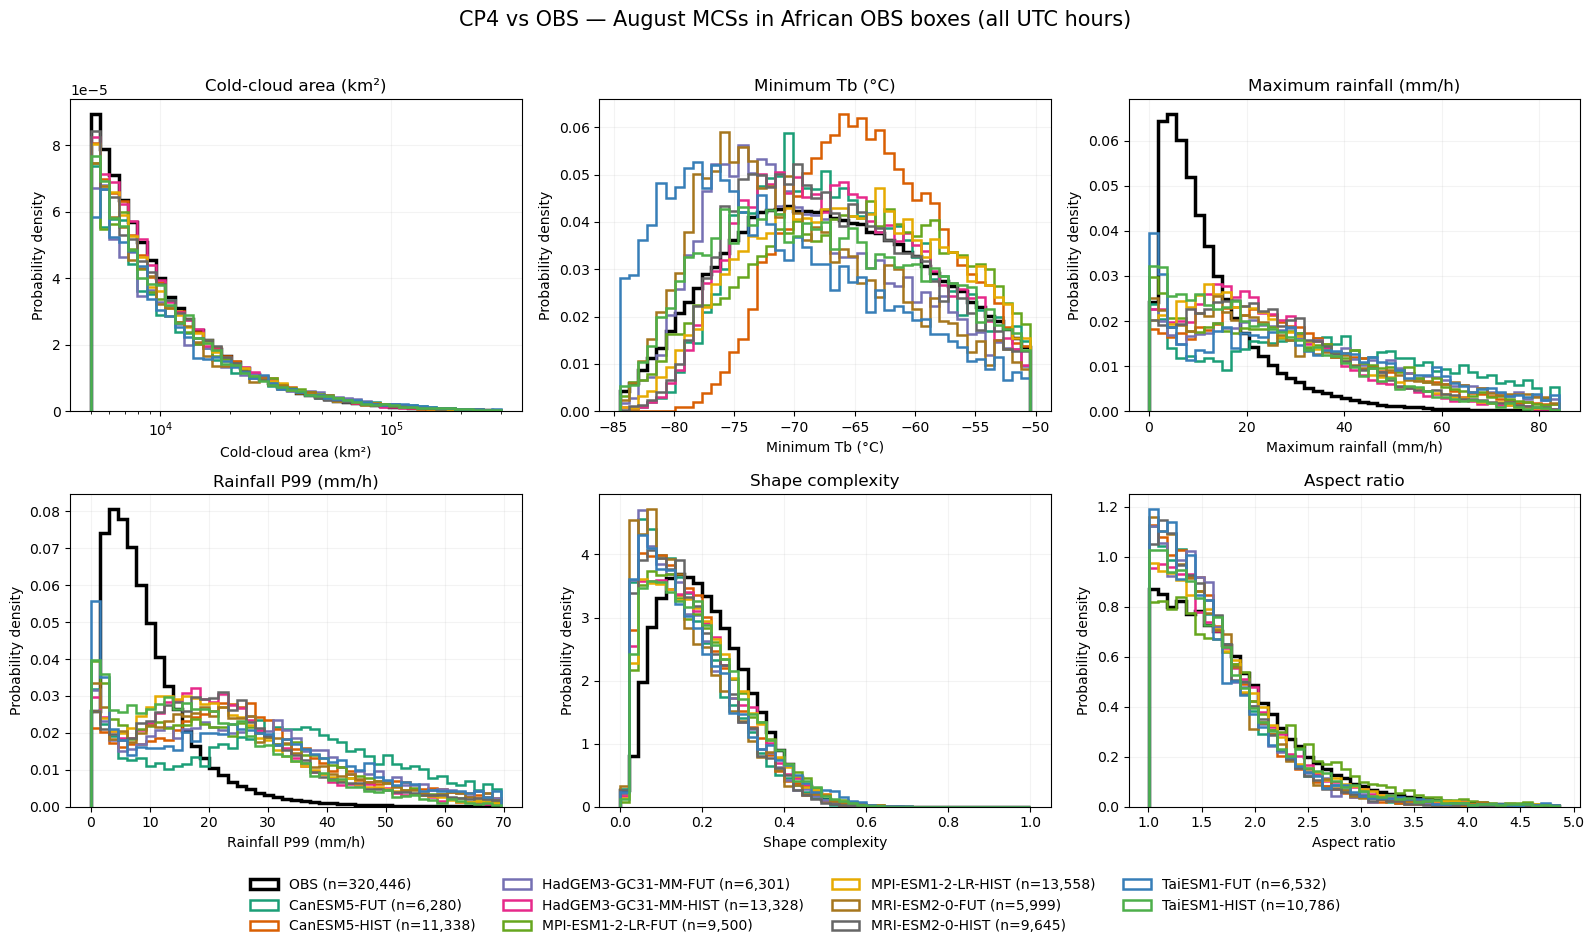

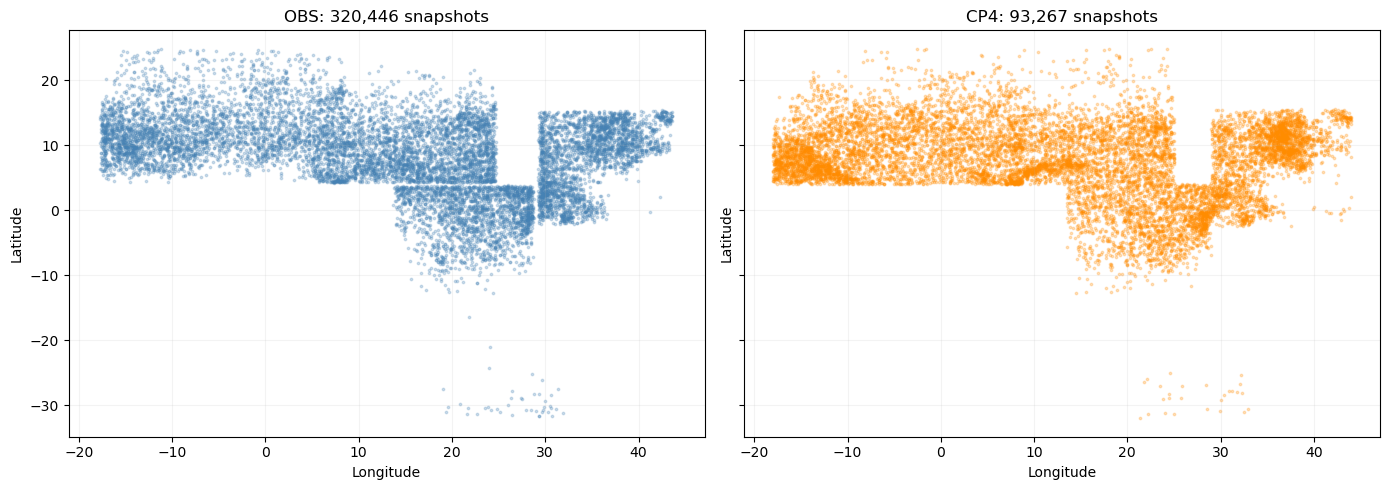

In [19]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from shared.COCOON import glob_util

# ============================================================
# SETTINGS
# ============================================================

BASE = Path(
    "/gws/ssde/j25b/cocoon/MCS_5000km2_tables_v3"
)

OBS_ROOT = BASE / "base_tables_tir-prcp"
CP4_ROOT = BASE / "CP4_base_tables_tir-prcp"

MONTH = 8
OBS_YEARS = range(2000, 2021)

# Specific model, or None to compare all completed models
RUN = None                  # e.g. "CanESM5-HIST"

# None = all hourly storms; 18 = only 18 UTC snapshots
STORM_HOUR_UTC = None

# Automatically find the African OBS regions.
# Adjust manually if any region uses a different naming convention.
AFRICA_REGIONS = [
    r for r in glob_util.REGIONS
    if "af" in r.lower() and (OBS_ROOT / r).is_dir()
]

assert AFRICA_REGIONS, "No African OBS regions found."

# Box format: [west, east, south, north]
BOXES = {
    r: glob_util.REGIONS[r][0]
    for r in AFRICA_REGIONS
}

print("African OBS regions:", AFRICA_REGIONS)
print("Region boxes:", BOXES)

COLS = [
    "date", "year", "month", "hour", "minute",
    "clon", "clat", "tminlat", "tminlon", "tmean",
    "area", "area50", "area60", "area70",
    "tmin", "precipitation_max",
    "precipitation_p99", "precipitation_area1mm", "precipitation_area3mm", "precipitation_area8mm",
    "shape_complexity", "aspect_ratio",
]

# ============================================================
# 1. LOAD OBS AUGUST STORMS FROM AFRICAN REGIONS
# ============================================================

obs_parts = []

for region in AFRICA_REGIONS:
    for year in OBS_YEARS:

        f = (
            OBS_ROOT / region /
            f"{year}_MCS_5000km2_-40C_0.1degTIR-IMERG_hourly.parquet"
        )

        if not f.exists():
            continue

        df = pd.read_parquet(
            f,
            columns=COLS,
            filters=[("month", "==", MONTH)]
        )

        df["region"] = region
        obs_parts.append(df)

if not obs_parts:
    raise FileNotFoundError("No OBS August Parquets found.")

obs = pd.concat(obs_parts, ignore_index=True)

# Exact duplicates can occur where regional boxes overlap.
n_before = len(obs)

obs = obs.drop_duplicates(
    subset=["date", "tminlat", "tminlon"]
).copy()

print(
    f"OBS: {len(obs):,} storm snapshots "
    f"({n_before-len(obs):,} overlap duplicates removed)"
)

# ============================================================
# 2. LOAD CP4 AUGUST STORMS
# ============================================================

cp4_files = sorted(
    CP4_ROOT.glob(f"*/year_*/month_{MONTH:02d}.parquet")
)

if RUN is not None:
    cp4_files = [
        f for f in cp4_files
        if f.parent.parent.name == RUN
    ]

if not cp4_files:
    raise FileNotFoundError("No completed CP4 August Parquets found.")

cp4_parts = []

for f in cp4_files:
    df = pd.read_parquet(
        f,
        columns=COLS + ["run", "storm_hour_end_utc"]
    )
    cp4_parts.append(df)

cp4 = pd.concat(cp4_parts, ignore_index=True)

print(f"CP4 before regional filtering: {len(cp4):,}")

# ============================================================
# 3. KEEP CP4 STORMS INSIDE THE UNION OF OBS AFRICA BOXES
# ============================================================

# Normalise model longitude to -180 ... 180
lon = ((cp4["clon"].to_numpy() + 180) % 360) - 180
lat = cp4["clat"].to_numpy()

inside = np.zeros(len(cp4), dtype=bool)

for west, east, south, north in BOXES.values():
    inside |= (
        (lon >= west) & (lon <= east) &
        (lat >= south) & (lat <= north)
    )

cp4 = cp4.loc[inside].copy()

print(f"CP4 inside OBS Africa boxes: {len(cp4):,}")

# ============================================================
# 4. OPTIONAL UTC HOUR FILTER
# ============================================================

if STORM_HOUR_UTC is not None:

    obs = obs.loc[
        obs["hour"] == STORM_HOUR_UTC
    ].copy()

    # CP4 hourly means are stamped at hh:30,
    # with the intended ending hour saved separately.
    cp4 = cp4.loc[
        np.isclose(
            cp4["storm_hour_end_utc"],
            STORM_HOUR_UTC
        )
    ].copy()

if obs.empty or cp4.empty:
    raise ValueError("No storms after month/region/hour filtering.")


# ============================================================
# 4b. REPORT ACTUAL TEMPORAL COVERAGE
# ============================================================

coverage_rows = []

datasets = [("OBS", obs, "hour")]

for run in sorted(cp4["run"].dropna().unique()):
    datasets.append((
        run,
        cp4.loc[cp4["run"] == run],
        "storm_hour_end_utc"
    ))

for name, df, hour_col in datasets:

    months = sorted(
        pd.to_numeric(df["month"], errors="coerce")
        .dropna().astype(int).unique()
    )

    years = sorted(
        pd.to_numeric(df["year"], errors="coerce")
        .dropna().astype(int).unique()
    )

    hours = sorted(
        pd.to_numeric(df[hour_col], errors="coerce")
        .dropna().round(3).unique()
    )

    hour_string = ", ".join(
        f"{int(h):02d}" if float(h).is_integer()
        else f"{h:05.2f}"
        for h in hours
    )

    coverage_rows.append({
        "Dataset": name,
        "Months": ", ".join(f"{m:02d}" for m in months),
        "Years": f"{min(years)}–{max(years)}" if years else "—",
        "N years": len(years),
        "Unique UTC hours": hour_string,
        "N hours": len(hours),
        "Storm snapshots": len(df)
    })

coverage = pd.DataFrame(coverage_rows)

print("\nTEMPORAL COVERAGE OF DATA USED IN THE PLOTS")
display(coverage.set_index("Dataset"))

# Optional: show available hours as a compact graphic
fig_cov, ax_cov = plt.subplots(
    figsize=(12, max(2, 0.5 * len(coverage) + 1))
)

for i, (name, df, hour_col) in enumerate(datasets):
    hours = pd.to_numeric(
        df[hour_col], errors="coerce"
    ).dropna().unique()

    ax_cov.scatter(
        hours, np.full(len(hours), i),
        s=55,
        color="black" if name == "OBS" else "steelblue"
    )

ax_cov.set_yticks(range(len(datasets)))
ax_cov.set_yticklabels([d[0] for d in datasets])
ax_cov.set_xticks(range(24))
ax_cov.set_xlim(-0.5, 23.5)
ax_cov.set_xlabel("UTC storm hour")
ax_cov.set_title("Hourly coverage of the datasets being compared")
ax_cov.invert_yaxis()
ax_cov.grid(axis="x", alpha=0.15)
plt.tight_layout()
plt.show()


# ============================================================
# 5. SUMMARY STATISTICS
# ============================================================

obs["dataset"] = "OBS"
cp4["dataset"] = cp4["run"]

all_mcs = pd.concat([obs, cp4], ignore_index=True)

summary = (
    all_mcs.groupby("dataset")
    .agg(
        n=("area", "size"),
        area_median=("area", "median"),
        area_p95=("area", lambda x: x.quantile(0.95)),
        tmin_median=("tmin", "median"),
        pmax_median=("precipitation_max", "median"),
        rain_p99_median=("precipitation_p99", "median"),
        complexity_median=("shape_complexity", "median"),
        aspect_median=("aspect_ratio", "median"),
    )
)

# Snapshot frequency normalised by number of sampled days
day_count = (
    all_mcs.assign(
        date_only=all_mcs["date"].astype(str).str[:10]
    )
    .groupby("dataset")["date_only"].nunique()
)

summary["snapshots_per_day"] = summary["n"] / day_count

display(summary.round(2))

# ============================================================
# 6. COMPARATIVE DISTRIBUTIONS
# ============================================================

metrics = [
    ("area", "Cold-cloud area (km²)", "log"),
    ("tmin", "Minimum Tb (°C)", "linear"),
    ("precipitation_max", "Maximum rainfall (mm/h)", "linear"),
    ("precipitation_p99", "Rainfall P99 (mm/h)", "linear"),
    ("shape_complexity", "Shape complexity", "linear"),
    ("aspect_ratio", "Aspect ratio", "linear"),
]

labels = ["OBS"] + sorted(cp4["run"].unique())

# ColourBrewer colours, OBS always black
palette = (
    list(plt.get_cmap("Dark2").colors) +
    [plt.get_cmap("Set1")(1), plt.get_cmap("Set1")(2)]
)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, (col, xlabel, scale) in zip(axes.flat, metrics):

    data = {
        label: pd.to_numeric(
            all_mcs.loc[all_mcs["dataset"] == label, col],
            errors="coerce"
        ).dropna().to_numpy()
        for label in labels
    }

    valid = np.concatenate([
        v[np.isfinite(v)] for v in data.values() if len(v)
    ])

    if scale == "log":
        bins = np.geomspace(5000, 300000, 45)
        ax.set_xscale("log")

    else:
        lower = (
            0 if col in [
                "precipitation_max",
                "precipitation_p99",
                "shape_complexity"
            ]
            else np.nanquantile(valid, 0.005)
        )

        upper = (
            1 if col == "shape_complexity"
            else np.nanquantile(valid, 0.995)
        )

        if upper <= lower:
            upper = lower + 1

        bins = np.linspace(lower, upper, 46)

    for i, label in enumerate(labels):

        x = data[label]
        x = x[np.isfinite(x)]

        if not len(x):
            continue

        ax.hist(
            x,
            bins=bins,
            density=True,
            histtype="step",
            linewidth=2.5 if label == "OBS" else 1.8,
            color="black" if label == "OBS" else palette[(i-1) % len(palette)],
            label=f"{label} (n={len(x):,})",
        )

    ax.set_title(xlabel)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Probability density")
    ax.grid(alpha=0.15)

handles, legend_labels = axes.flat[0].get_legend_handles_labels()

fig.legend(
    handles, legend_labels,
    loc="lower center",
    ncol=min(len(labels), 4),
    bbox_to_anchor=(0.5, -0.02),
    frameon=False
)

hour_title = (
    "all UTC hours"
    if STORM_HOUR_UTC is None
    else f"{STORM_HOUR_UTC:02d} UTC"
)

fig.suptitle(
    f"CP4 vs OBS — August MCSs in African OBS boxes ({hour_title})",
    fontsize=15, y=1.02
)

plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

# ============================================================
# 7. OPTIONAL GEOGRAPHICAL COMPARISON
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

for ax, df, title, colour in zip(
    axes,
    [obs, cp4],
    ["OBS", "CP4"],
    ["steelblue", "darkorange"]
):
    sample = df.sample(
        min(len(df), 12000),
        random_state=42
    )

    ax.scatter(
        ((sample["clon"] + 180) % 360) - 180,
        sample["clat"],
        s=3, alpha=0.25, color=colour,
        rasterized=True
    )

    ax.set_title(f"{title}: {len(df):,} snapshots")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()



Rainfall exceedance thresholds: P90
OBS: 27.30 mm/h
CanESM5: 57.36 mm/h
HadGEM3-GC31-MM: 47.58 mm/h
MPI-ESM1-2-LR: 49.67 mm/h
MRI-ESM2-0: 50.85 mm/h
TaiESM1: 48.59 mm/h


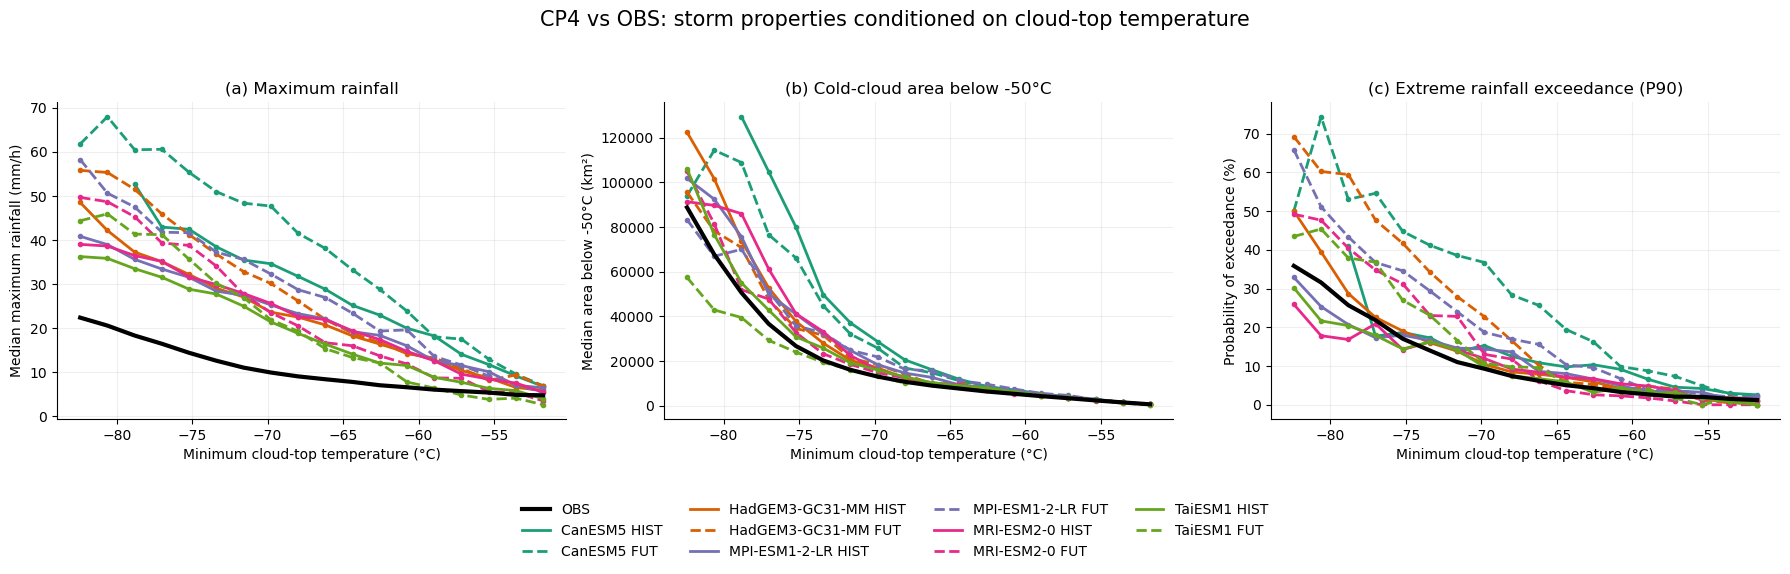

In [20]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# SETTINGS
# ============================================================

EXTREME_PERCENTILE = 90    # Change here: 95, 98, 99, 99.5 ...
N_TMIN_BINS = 18
MIN_STORMS_PER_BIN = 10

# Uses obs and cp4 from the previous notebook cell
# Both should already be restricted to August and African OBS boxes.
obs_plot = obs.copy()
cp4_plot = cp4.copy()

# Optional additional hour selection.
# None = use all hours currently loaded in obs and cp4.
# 18   = 18 UTC storm snapshots only.
HOUR_UTC = None

if HOUR_UTC is not None:
    obs_plot = obs_plot.loc[
        obs_plot["hour"] == HOUR_UTC
    ].copy()

    cp4_plot = cp4_plot.loc[
        np.isclose(cp4_plot["storm_hour_end_utc"], HOUR_UTC)
    ].copy()

# ============================================================
# 1. HISTORICAL RAINFALL THRESHOLDS
# ============================================================

def valid_values(df, column):
    x = pd.to_numeric(df[column], errors="coerce").to_numpy()
    return x[np.isfinite(x)]

# Observations use their own overall pmax percentile.
obs_pmax = valid_values(obs_plot, "precipitation_max")
obs_threshold = np.percentile(
    obs_pmax, EXTREME_PERCENTILE
)

# Identify all distinct CP4 driving models.
models = sorted({
    run.rsplit("-", 1)[0]
    for run in cp4_plot["run"].dropna().unique()
})

# Each future simulation uses its own historical model threshold.
thresholds = {}
models_to_plot = []

for model in models:

    hist = cp4_plot.loc[
        cp4_plot["run"] == f"{model}-HIST"
    ]

    hist_pmax = valid_values(hist, "precipitation_max")

    if len(hist_pmax) == 0:
        print(f"Skipping {model}: no HIST baseline available")
        continue

    thresholds[model] = np.percentile(
        hist_pmax, EXTREME_PERCENTILE
    )
    models_to_plot.append(model)

print(f"\nRainfall exceedance thresholds: P{EXTREME_PERCENTILE}")
print(f"OBS: {obs_threshold:.2f} mm/h")

for model in models_to_plot:
    print(f"{model}: {thresholds[model]:.2f} mm/h")

# ============================================================
# 2. COMMON TMIN BINS ACROSS ALL DATASETS
# ============================================================

all_tmin = np.concatenate([
    valid_values(obs_plot, "tmin"),
    valid_values(cp4_plot, "tmin")
])

# Trim only the Tmin plotting range, using common bounds.
tmin_low, tmin_high = np.percentile(all_tmin, [1, 99])

tmin_edges = np.linspace(
    tmin_low, tmin_high, N_TMIN_BINS + 1
)

tmin_centres = 0.5 * (
    tmin_edges[:-1] + tmin_edges[1:]
)

# ============================================================
# 3. CALCULATE BINNED RELATIONSHIPS
# ============================================================

def calculate_profile(df, rainfall_threshold):
    """
    Returns three Tmin-binned series:
       1. Median pmax
       2. Median cloud area below -50C
       3. Probability (%) of pmax > baseline threshold

    Bins containing fewer than MIN_STORMS_PER_BIN
    valid storms are masked as NaN.
    """

    tmin = pd.to_numeric(
        df["tmin"], errors="coerce"
    ).to_numpy()

    pmax = pd.to_numeric(
        df["precipitation_max"], errors="coerce"
    ).to_numpy()

    area50 = pd.to_numeric(
        df["area50"], errors="coerce"
    ).to_numpy()

    pmax_median = np.full(N_TMIN_BINS, np.nan)
    area50_median = np.full(N_TMIN_BINS, np.nan)
    exceedance = np.full(N_TMIN_BINS, np.nan)
    counts = np.zeros(N_TMIN_BINS, dtype=int)

    for b in range(N_TMIN_BINS):

        if b == N_TMIN_BINS - 1:
            mask = (
                (tmin >= tmin_edges[b]) &
                (tmin <= tmin_edges[b + 1])
            )
        else:
            mask = (
                (tmin >= tmin_edges[b]) &
                (tmin < tmin_edges[b + 1])
            )

        p = pmax[mask]
        a = area50[mask]

        p = p[np.isfinite(p)]
        a = a[np.isfinite(a)]

        counts[b] = len(p)

        if len(p) >= MIN_STORMS_PER_BIN:
            pmax_median[b] = np.median(p)
            exceedance[b] = 100 * np.mean(
                p > rainfall_threshold
            )

        if len(a) >= MIN_STORMS_PER_BIN:
            area50_median[b] = np.median(a)

    return pmax_median, area50_median, exceedance, counts


# ============================================================
# 4. PLOT ALL HIST/FUT PAIRS + OBS
# ============================================================

fig, axes = plt.subplots(
    1, 3, figsize=(18, 5.5), sharex=True
)

# ColourBrewer Dark2, same colour for HIST and FUT.
colors = plt.get_cmap("Dark2").colors
model_colors = {
    model: colors[i % len(colors)]
    for i, model in enumerate(models_to_plot)
}

# Model curves
for model in models_to_plot:

    color = model_colors[model]
    threshold = thresholds[model]

    for experiment, linestyle in [
        ("HIST", "-"),
        ("FUT", "--")
    ]:

        run = f"{model}-{experiment}"
        df = cp4_plot.loc[cp4_plot["run"] == run]

        if df.empty:
            continue

        pmed, amed, prob, counts = calculate_profile(
            df, threshold
        )

        label = f"{model} {experiment}"

        for ax, y in zip(axes, [pmed, amed, prob]):
            ax.plot(
                tmin_centres, y,
                color=color,
                linestyle=linestyle,
                linewidth=2,
                marker="o",
                markersize=3,
                label=label,
            )

# OBS curve
obs_pmed, obs_amed, obs_prob, obs_counts = (
    calculate_profile(obs_plot, obs_threshold)
)

for ax, y in zip(
    axes, [obs_pmed, obs_amed, obs_prob]
):
    ax.plot(
        tmin_centres, y,
        color="black",
        linewidth=3,
        label="OBS",
        zorder=10
    )

# ============================================================
# 5. FORMATTING
# ============================================================

axes[0].set_title("(a) Maximum rainfall")
axes[0].set_ylabel("Median maximum rainfall (mm/h)")

axes[1].set_title("(b) Cold-cloud area below -50°C")
axes[1].set_ylabel("Median area below -50°C (km²)")

axes[2].set_title(
    f"(c) Extreme rainfall exceedance (P{EXTREME_PERCENTILE})"
)
axes[2].set_ylabel("Probability of exceedance (%)")

for ax in axes:
    ax.set_xlabel("Minimum cloud-top temperature (°C)")
    ax.grid(alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# One shared legend
legend_handles = [
    Line2D([0], [0], color="black", lw=3, label="OBS")
]

for model in models_to_plot:
    for experiment, linestyle in [
        ("HIST", "-"), ("FUT", "--")
    ]:
        run = f"{model}-{experiment}"

        if not (cp4_plot["run"] == run).any():
            continue

        legend_handles.append(
            Line2D(
                [0], [0],
                color=model_colors[model],
                lw=2,
                linestyle=linestyle,
                label=f"{model} {experiment}"
            )
        )

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.04),
    frameon=False
)

fig.suptitle(
    "CP4 vs OBS: storm properties conditioned on cloud-top temperature",
    fontsize=15
)

plt.tight_layout(rect=[0, 0.13, 1, 0.94])
plt.show()


Rainfall exceedance thresholds: P99
  OBS                      54.79 mm/h
  CanESM5                  86.57 mm/h
  HadGEM3-GC31-MM          75.74 mm/h
  MPI-ESM1-2-LR            75.16 mm/h
  MRI-ESM2-0               80.86 mm/h
  TaiESM1                  74.85 mm/h


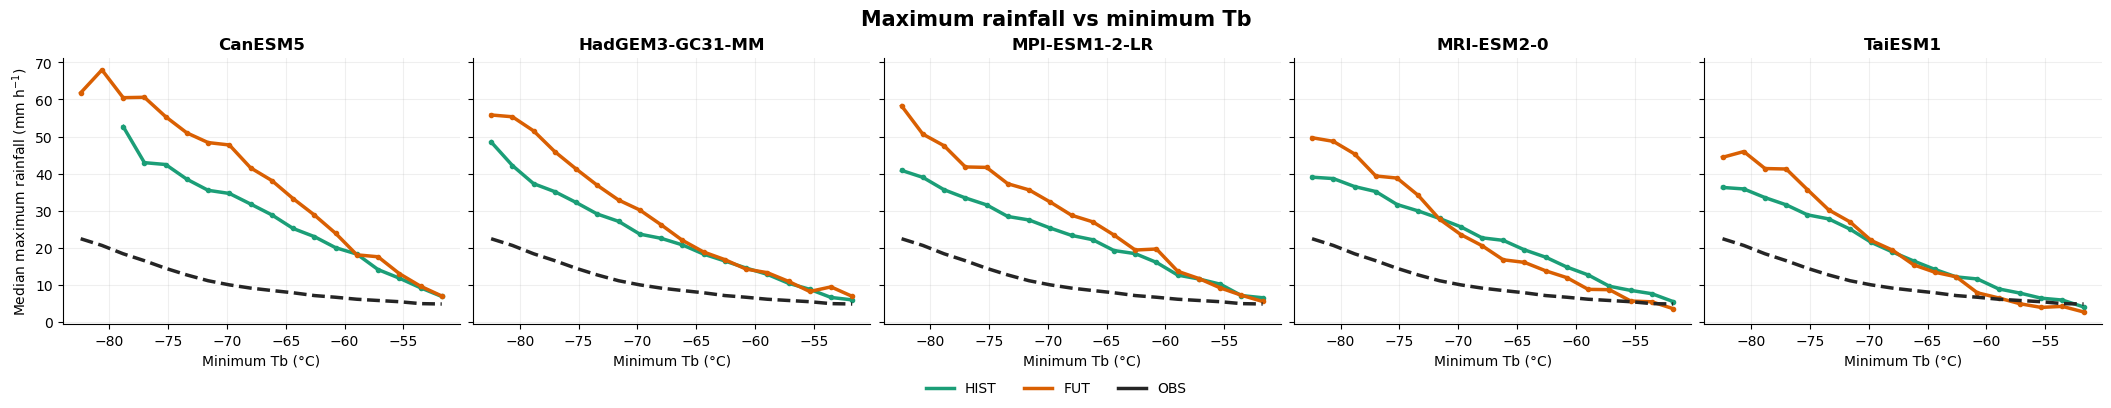

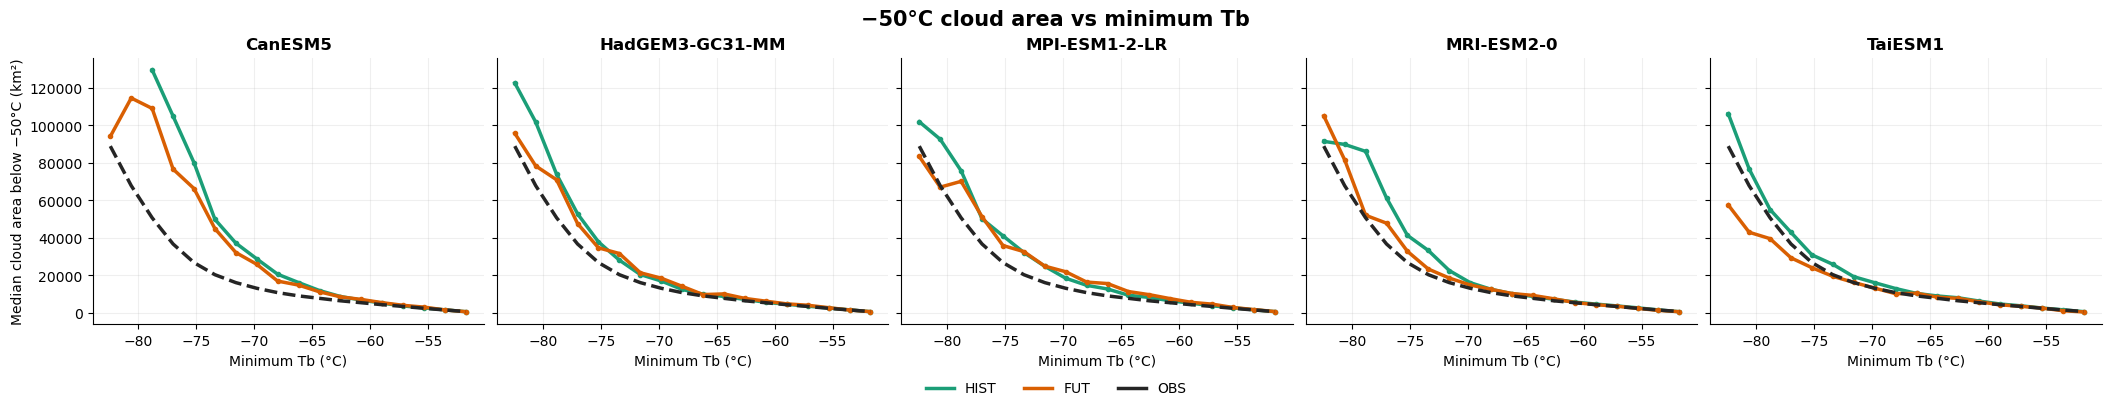

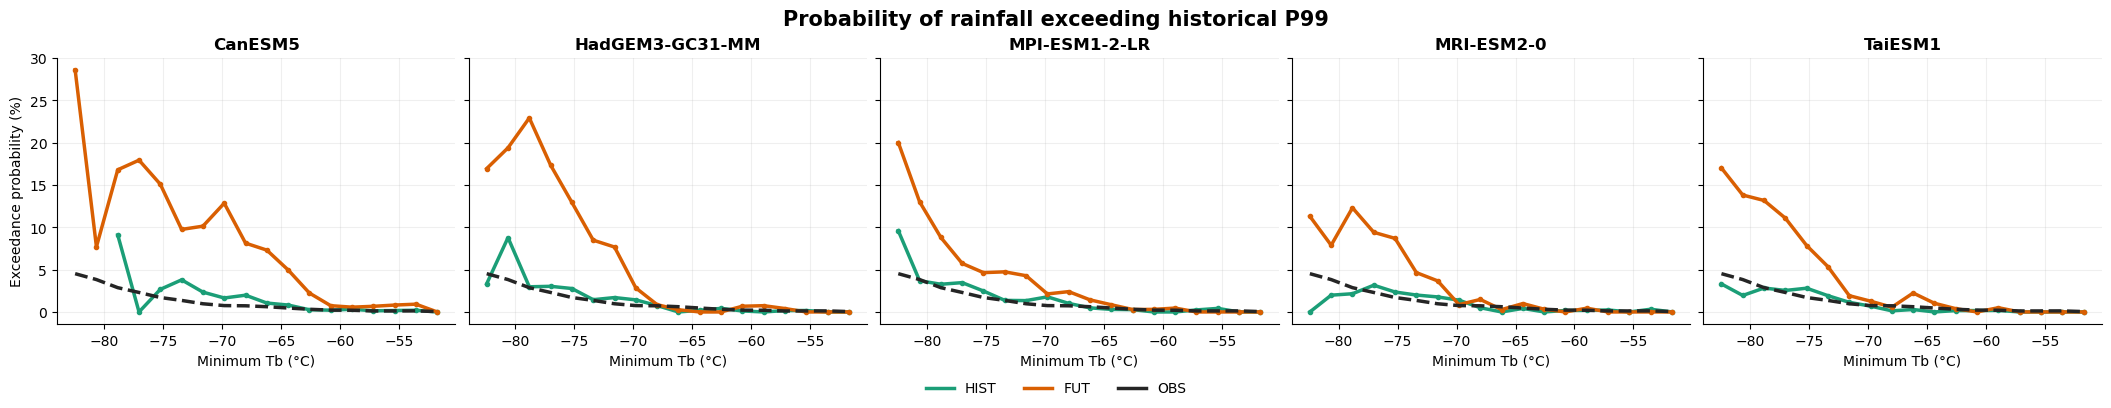

In [21]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# SETTINGS
# ============================================================

EXTREME_PERCENTILE = 99       # Change to 95, 98, 99.5, etc.
N_TMIN_BINS = 18
MIN_STORMS_PER_BIN = 10
HOUR_UTC = None               # None = all hours; 18 = 18 UTC only

# Choose which figures to produce
PLOT_METRICS = [
    "pmax",
    "area50",
    "exceedance"
]

MODELS = [
    "CanESM5",
    "HadGEM3-GC31-MM",
    "MPI-ESM1-2-LR",
    "MRI-ESM2-0",
    "TaiESM1"
]

# ColourBrewer Dark2
C_HIST = "#1b9e77"
C_FUT = "#d95f02"
C_OBS = "#252525"

# ============================================================
# 1. PREPARE DATA
# ============================================================

obs_use = obs.copy()
cp4_use = cp4.copy()

if HOUR_UTC is not None:
    obs_use = obs_use.loc[
        obs_use["hour"] == HOUR_UTC
    ].copy()

    cp4_use = cp4_use.loc[
        np.isclose(cp4_use["storm_hour_end_utc"], HOUR_UTC)
    ].copy()

for name, df in [("OBS", obs_use), ("CP4", cp4_use)]:
    required = [
        "tmin", "precipitation_max", "area50"
    ]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise KeyError(
            f"{name} missing columns {missing}. "
            "Reload the original Parquets including area50."
        )

def finite_values(df, column):
    x = pd.to_numeric(
        df[column], errors="coerce"
    ).to_numpy(dtype=float)
    return x[np.isfinite(x)]

# Common Tmin range and bins for OBS and all models
all_tmin = np.concatenate([
    finite_values(obs_use, "tmin"),
    finite_values(cp4_use, "tmin")
])

tmin_min, tmin_max = np.percentile(all_tmin, [1, 99])

edges = np.linspace(
    tmin_min, tmin_max, N_TMIN_BINS + 1
)
centres = 0.5 * (edges[:-1] + edges[1:])

# ============================================================
# 2. HISTORICAL EXTREME RAINFALL THRESHOLDS
# ============================================================

thresholds = {}

obs_pmax = finite_values(obs_use, "precipitation_max")
thresholds["OBS"] = np.percentile(
    obs_pmax, EXTREME_PERCENTILE
)

for model in MODELS:
    hist = cp4_use.loc[
        cp4_use["run"] == model + "-HIST"
    ]

    pmax = finite_values(hist, "precipitation_max")

    thresholds[model] = (
        np.percentile(pmax, EXTREME_PERCENTILE)
        if len(pmax) else np.nan
    )

print(f"Rainfall exceedance thresholds: P{EXTREME_PERCENTILE}")
for model, threshold in thresholds.items():
    print(f"  {model:22s} {threshold:7.2f} mm/h")

# ============================================================
# 3. BINNED PROFILE FUNCTION
# ============================================================

def binned_profile(df, threshold):

    t = pd.to_numeric(
        df["tmin"], errors="coerce"
    ).to_numpy(dtype=float)

    p = pd.to_numeric(
        df["precipitation_max"], errors="coerce"
    ).to_numpy(dtype=float)

    a = pd.to_numeric(
        df["area50"], errors="coerce"
    ).to_numpy(dtype=float)

    result = {
        "pmax": np.full(N_TMIN_BINS, np.nan),
        "area50": np.full(N_TMIN_BINS, np.nan),
        "exceedance": np.full(N_TMIN_BINS, np.nan),
        "n": np.zeros(N_TMIN_BINS, dtype=int)
    }

    for i in range(N_TMIN_BINS):

        if i == N_TMIN_BINS - 1:
            mask = (t >= edges[i]) & (t <= edges[i+1])
        else:
            mask = (t >= edges[i]) & (t < edges[i+1])

        pv = p[mask & np.isfinite(p)]
        av = a[mask & np.isfinite(a)]

        result["n"][i] = len(pv)

        if len(pv) >= MIN_STORMS_PER_BIN:
            result["pmax"][i] = np.median(pv)

            if np.isfinite(threshold):
                result["exceedance"][i] = (
                    100 * np.mean(pv > threshold)
                )

        if len(av) >= MIN_STORMS_PER_BIN:
            result["area50"][i] = np.median(av)

    return result

# Calculate once, reuse for all figures
profiles = {
    "OBS": binned_profile(obs_use, thresholds["OBS"])
}

for model in MODELS:
    for exp in ["HIST", "FUT"]:

        run = f"{model}-{exp}"
        df = cp4_use.loc[cp4_use["run"] == run]

        profiles[run] = binned_profile(
            df, thresholds[model]
        )

# ============================================================
# 4. PLOT EACH METRIC AS A 1 x 5 FIGURE
# ============================================================

METRIC_INFO = {
    "pmax": {
        "title": "Maximum rainfall vs minimum Tb",
        "ylabel": "Median maximum rainfall (mm h$^{-1}$)",
    },
    "area50": {
        "title": "−50°C cloud area vs minimum Tb",
        "ylabel": "Median cloud area below −50°C (km²)",
    },
    "exceedance": {
        "title": (
            f"Probability of rainfall exceeding "
            f"historical P{EXTREME_PERCENTILE}"
        ),
        "ylabel": "Exceedance probability (%)",
    }
}

legend_handles = [
    Line2D([0], [0], color=C_HIST, lw=2.5, label="HIST"),
    Line2D([0], [0], color=C_FUT, lw=2.5, label="FUT"),
    Line2D([0], [0], color=C_OBS, lw=2.5, label="OBS"),
]

for metric in PLOT_METRICS:

    info = METRIC_INFO[metric]

    fig, axes = plt.subplots(
        1, 5,
        figsize=(21, 4),
        sharex=True,
        sharey=True,
        constrained_layout=True
    )

    for i, model in enumerate(MODELS):

        ax = axes[i]

        hist = profiles[f"{model}-HIST"][metric]
        fut = profiles[f"{model}-FUT"][metric]
        observational = profiles["OBS"][metric]

        ax.plot(
            centres, hist,
            color=C_HIST,
            lw=2.5,
            marker="o",
            markersize=3,
            label="HIST"
        )

        ax.plot(
            centres, fut,
            color=C_FUT,
            lw=2.5,
            marker="o",
            markersize=3,
            label="FUT"
        )

        ax.plot(
            centres, observational,
            color=C_OBS,
            lw=2.5,
            linestyle="--",
            label="OBS",
            zorder=10
        )

        ax.set_title(model, fontsize=12, fontweight="bold")
        ax.set_xlabel("Minimum Tb (°C)")
        ax.grid(alpha=0.2)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        if i == 0:
            ax.set_ylabel(info["ylabel"])

    fig.suptitle(
        info["title"],
        fontsize=15,
        fontweight="bold"
    )

    fig.legend(
        handles=legend_handles,
        loc="outside lower center",
        ncol=3,
        frameon=False
    )

    plt.show()


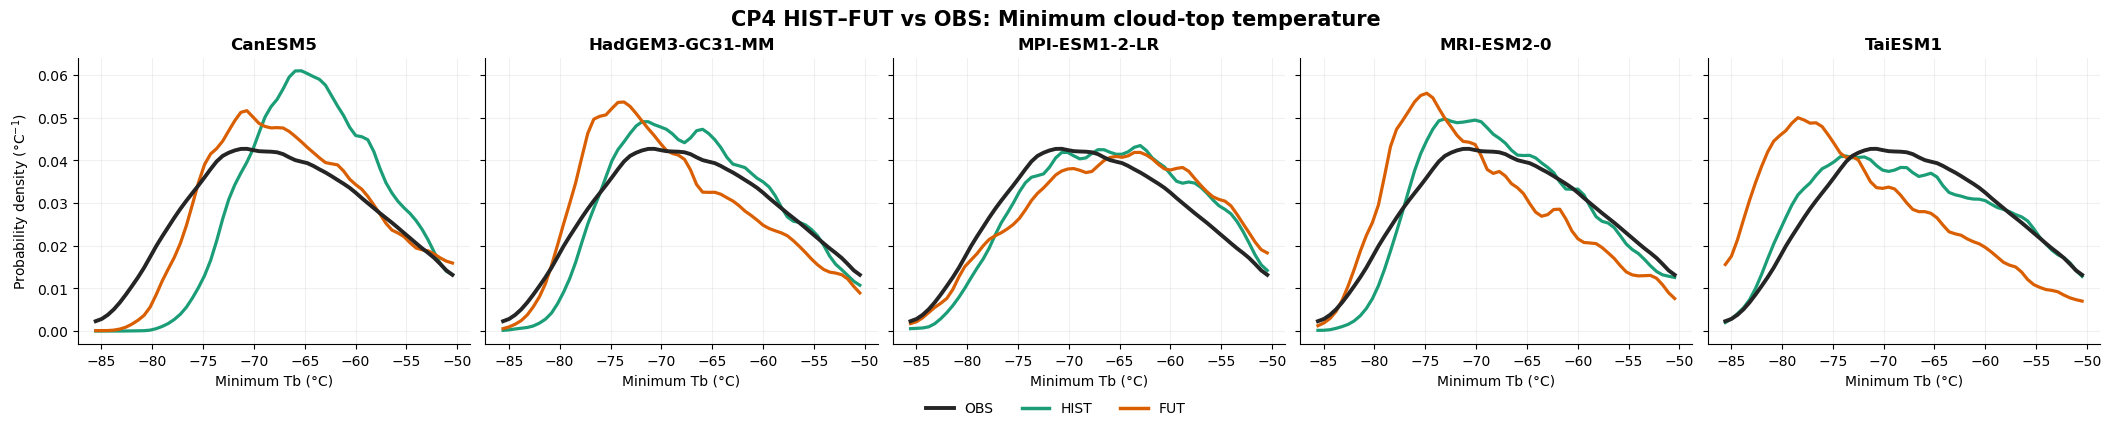

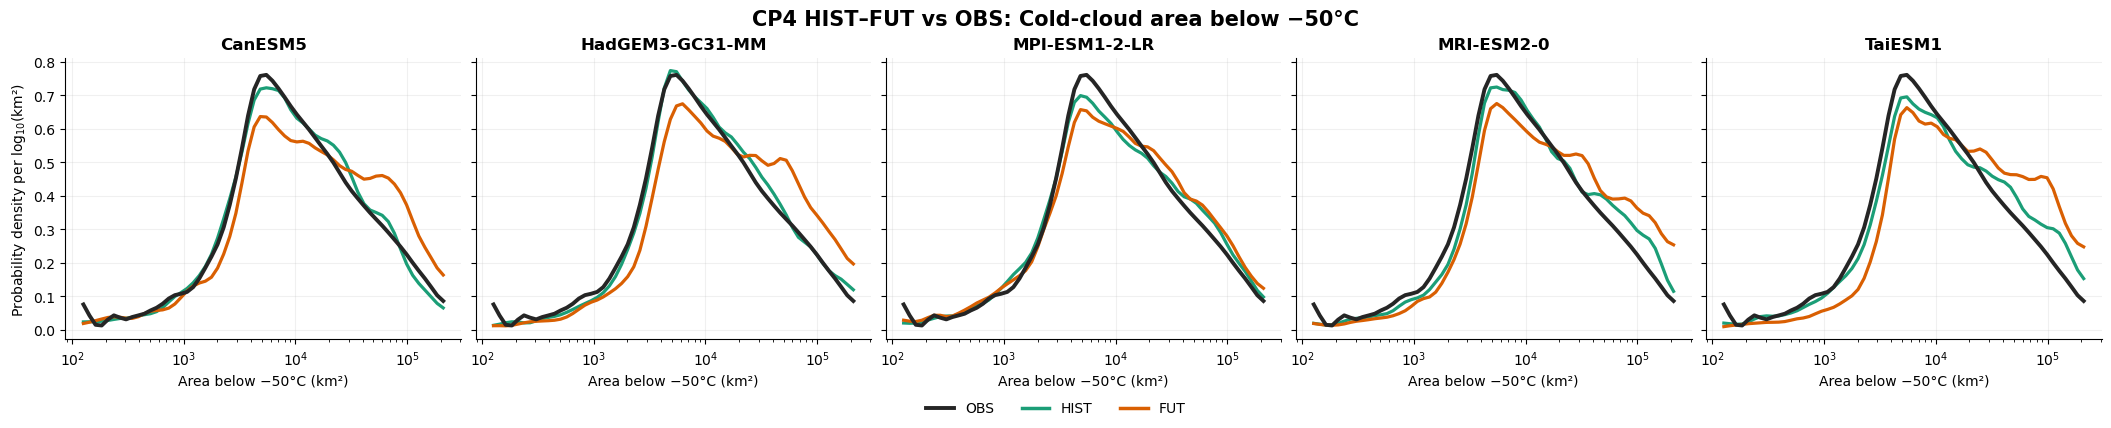

In [22]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from matplotlib.lines import Line2D

# ============================================================
# SETTINGS
# ============================================================

HOUR_UTC = None          # None = all available hours; 18 = 18 UTC

N_BINS = 60
SMOOTH_SIGMA = 1.2       # Gaussian smoothing in histogram bins
CLIP_PERCENTILES = (0.2, 99.8)

MODELS = [
    "CanESM5",
    "HadGEM3-GC31-MM",
    "MPI-ESM1-2-LR",
    "MRI-ESM2-0",
    "TaiESM1",
]

C_HIST = "#1b9e77"
C_FUT  = "#d95f02"
C_OBS  = "#252525"

# ============================================================
# 1. PREPARE DATA
# ============================================================

obs_pdf = obs.copy()
cp4_pdf = cp4.copy()

if HOUR_UTC is not None:

    obs_pdf = obs_pdf.loc[
        obs_pdf["hour"] == HOUR_UTC
    ].copy()

    cp4_pdf = cp4_pdf.loc[
        np.isclose(cp4_pdf["storm_hour_end_utc"], HOUR_UTC)
    ].copy()

for name, df in [("OBS", obs_pdf), ("CP4", cp4_pdf)]:
    missing = [
        c for c in ["tmin", "area50"]
        if c not in df.columns
    ]
    if missing:
        raise KeyError(
            f"{name} missing {missing}. "
            "Rerun the Parquet-loading cell including area50."
        )


def get_values(df, variable):
    x = pd.to_numeric(
        df[variable], errors="coerce"
    ).to_numpy(dtype=float)

    x = x[np.isfinite(x)]

    if variable == "area50":
        x = x[x > 0]

    return x


# ============================================================
# 2. COMMON BINS / PDF FUNCTION
# ============================================================

def make_common_edges(variable):

    values = np.concatenate([
        get_values(obs_pdf, variable),
        get_values(cp4_pdf, variable)
    ])

    # Work in log10(area) for the area PDFs
    if variable == "area50":
        values = np.log10(values)

    lo, hi = np.percentile(
        values, CLIP_PERCENTILES
    )

    return np.linspace(lo, hi, N_BINS + 1)


def make_pdf(values, edges, log_area=False):

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if log_area:
        values = values[values > 0]
        values = np.log10(values)

    if len(values) == 0:
        return np.full(len(edges) - 1, np.nan)

    counts, _ = np.histogram(values, bins=edges)

    # Normalise within the displayed range
    if counts.sum() == 0:
        return np.full(len(counts), np.nan)

    density = counts.astype(float) / (
        counts.sum() * np.diff(edges)
    )

    # Smooth slightly to give readable curves
    if SMOOTH_SIGMA > 0:
        density = gaussian_filter1d(
            density, sigma=SMOOTH_SIGMA
        )

        # Renormalise following smoothing
        integral = np.sum(density * np.diff(edges))
        density /= integral

    return density


# ============================================================
# 3. GENERATE THE TWO 1 x 5 FIGURES
# ============================================================

plot_settings = [
    {
        "variable": "tmin",
        "title": "Minimum cloud-top temperature",
        "xlabel": "Minimum Tb (°C)",
        "ylabel": "Probability density (°C$^{-1}$)",
        "log_area": False,
    },
    {
        "variable": "area50",
        "title": "Cold-cloud area below −50°C",
        "xlabel": "Area below −50°C (km²)",
        "ylabel": "Probability density per log$_{10}$(km²)",
        "log_area": True,
    },
]

legend_handles = [
    Line2D([0], [0], color=C_OBS, lw=2.8, label="OBS"),
    Line2D([0], [0], color=C_HIST, lw=2.5, label="HIST"),
    Line2D([0], [0], color=C_FUT, lw=2.5, label="FUT"),
]

for cfg in plot_settings:

    variable = cfg["variable"]
    log_area = cfg["log_area"]

    edges = make_common_edges(variable)
    centres = 0.5 * (edges[:-1] + edges[1:])

    if log_area:
        xaxis = 10 ** centres
    else:
        xaxis = centres

    # OBS PDF calculated once and reused in every panel
    obs_values = get_values(obs_pdf, variable)

    obs_density = make_pdf(
        obs_values, edges, log_area=log_area
    )

    fig, axes = plt.subplots(
        1, 5,
        figsize=(21, 4.2),
        sharex=True,
        sharey=True,
        constrained_layout=True
    )

    for i, model in enumerate(MODELS):

        ax = axes[i]

        # OBS
        ax.plot(
            xaxis, obs_density,
            color=C_OBS,
            lw=2.8,
            label="OBS",
            zorder=10,
        )

        # HIST and FUT
        for exp, color in [
            ("HIST", C_HIST),
            ("FUT", C_FUT),
        ]:

            run = f"{model}-{exp}"

            df = cp4_pdf.loc[
                cp4_pdf["run"] == run
            ]

            values = get_values(df, variable)

            if not len(values):
                continue

            density = make_pdf(
                values, edges, log_area=log_area
            )

            ax.plot(
                xaxis, density,
                color=color,
                lw=2.3,
                label=exp,
            )

        ax.set_title(
            model,
            fontsize=12,
            fontweight="bold"
        )

        ax.set_xlabel(cfg["xlabel"])

        if i == 0:
            ax.set_ylabel(cfg["ylabel"])

        if log_area:
            ax.set_xscale("log")

        ax.grid(alpha=0.18)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    fig.suptitle(
        f"CP4 HIST–FUT vs OBS: {cfg['title']}",
        fontsize=15,
        fontweight="bold"
    )

    fig.legend(
        handles=legend_handles,
        loc="outside lower center",
        ncol=3,
        frameon=False,
    )

    plt.show()


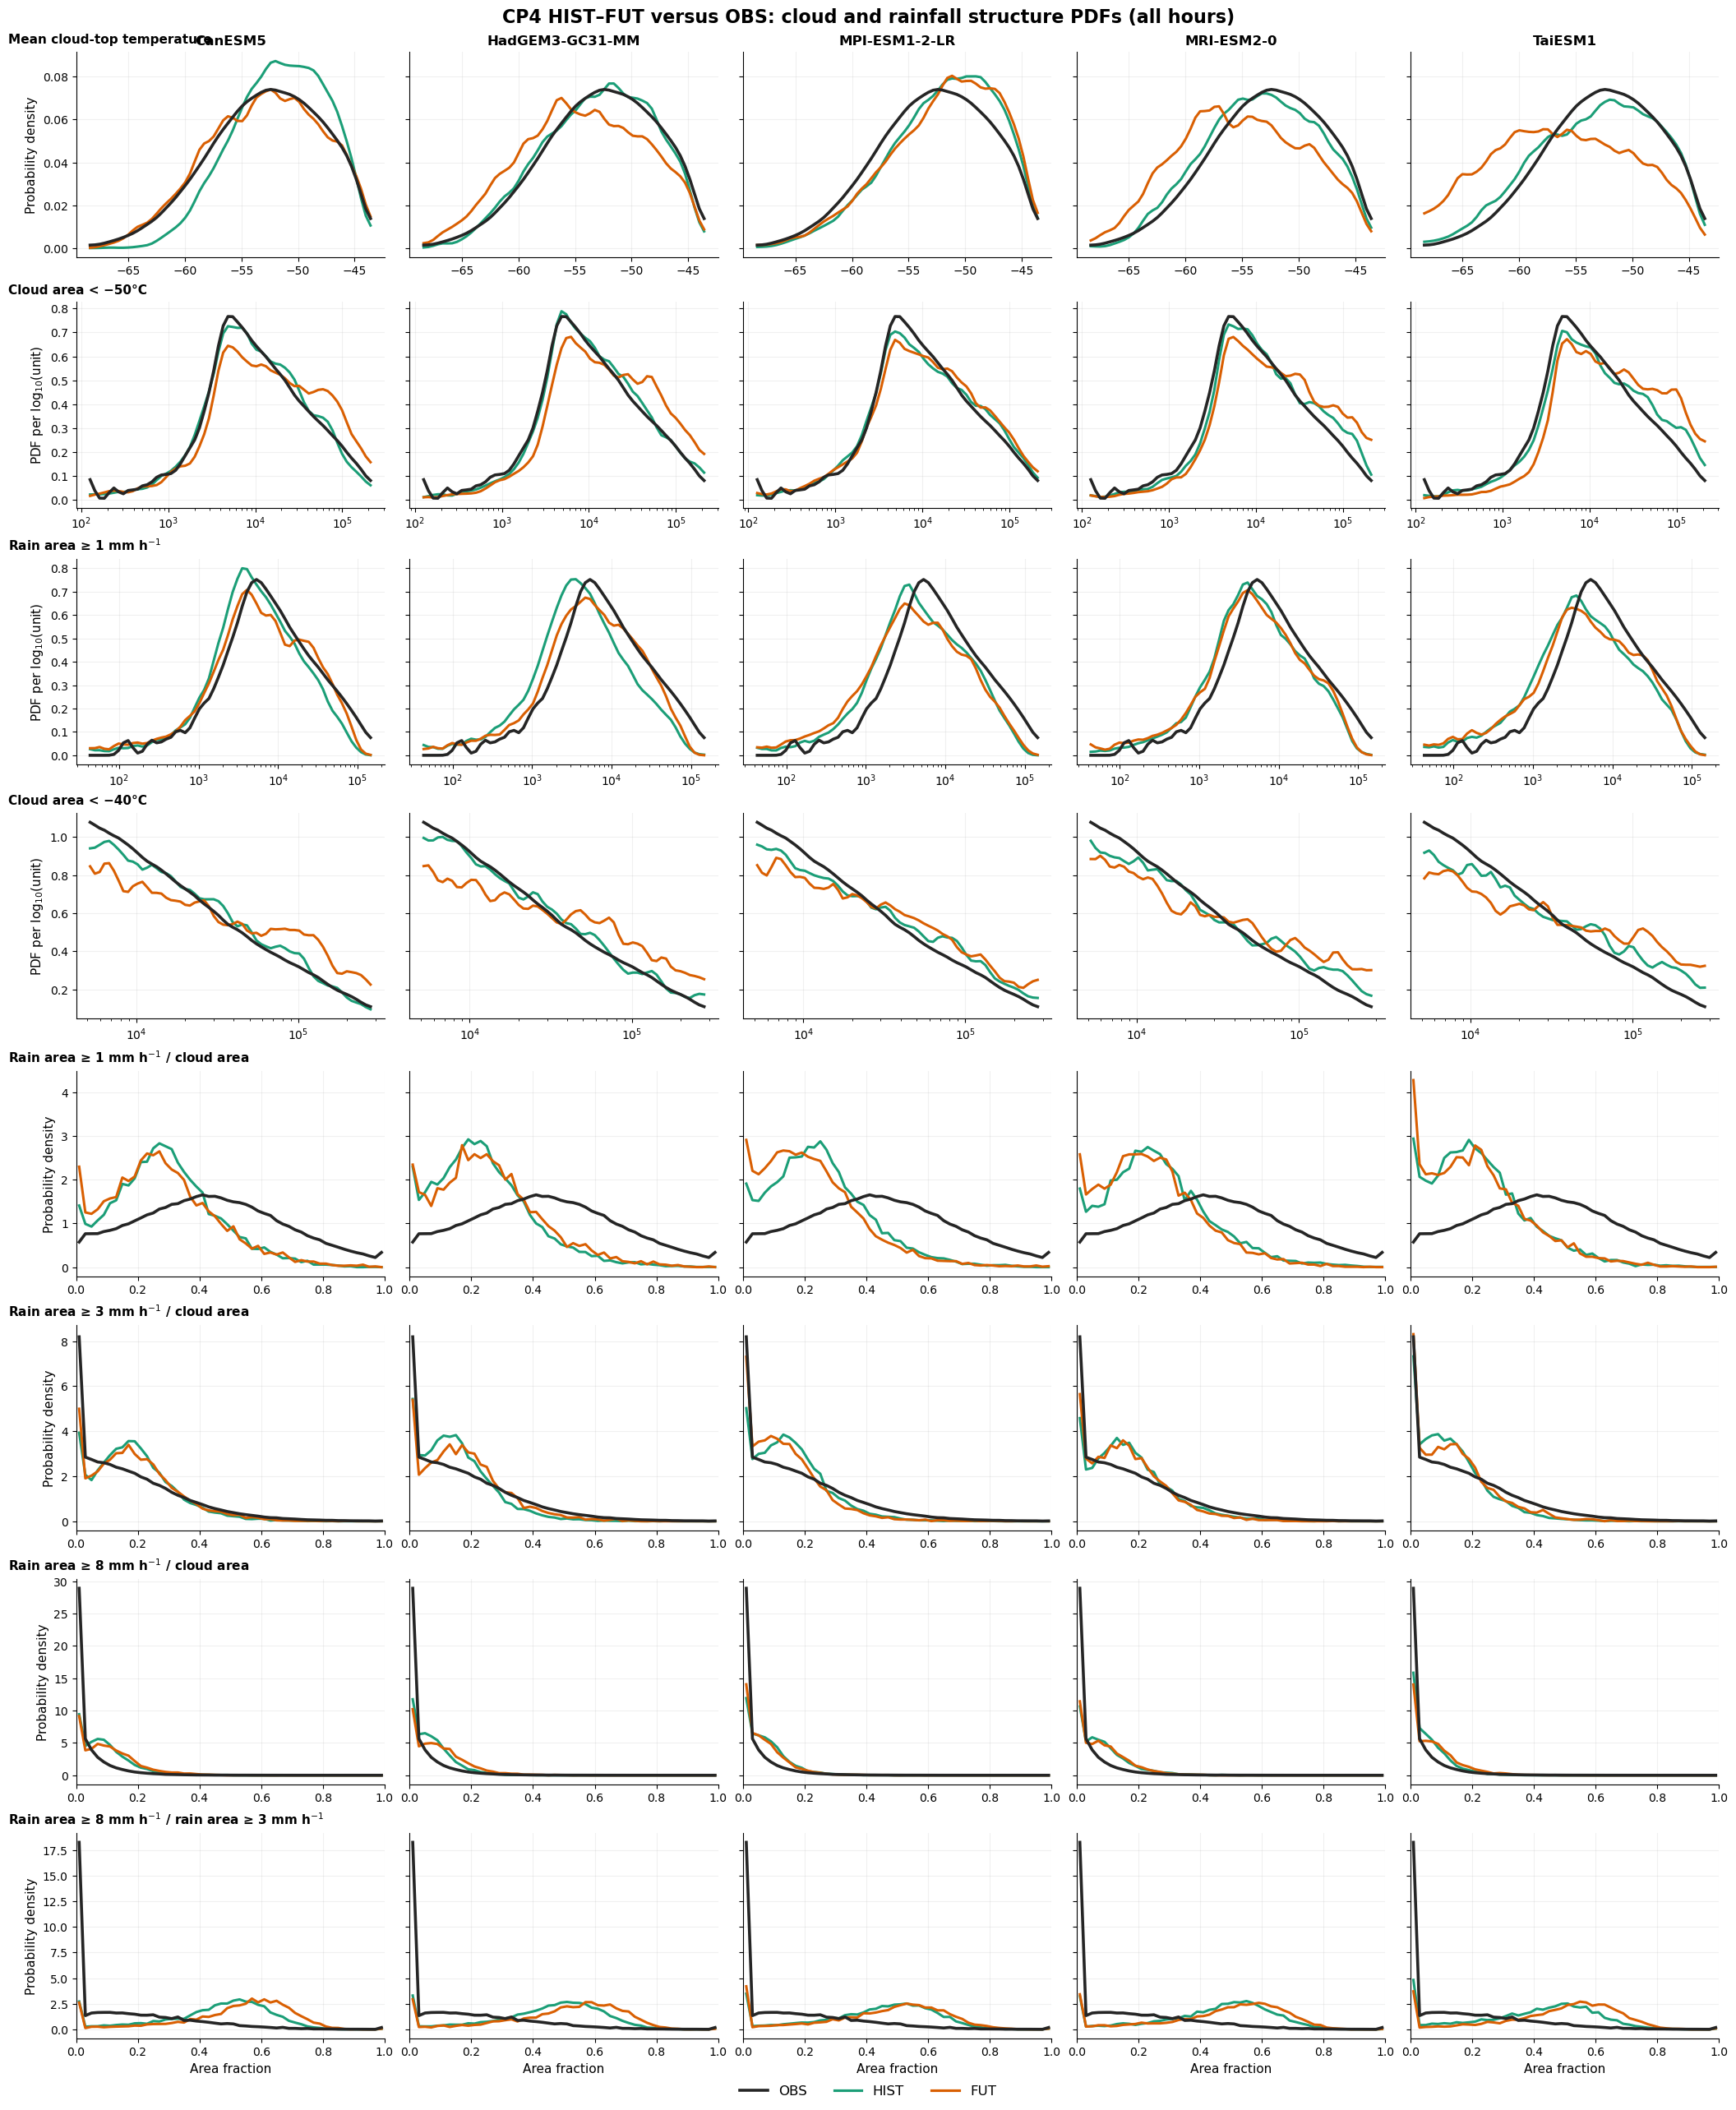

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from matplotlib.lines import Line2D

# ============================================================
# SETTINGS
# ============================================================

HOUR_UTC = None          # None = all hours; 18 = 18 UTC only

MODELS = [
    "CanESM5",
    "HadGEM3-GC31-MM",
    "MPI-ESM1-2-LR",
    "MRI-ESM2-0",
    "TaiESM1",
]

# Number of bins
N_BINS_LINEAR = 60
N_BINS_LOG = 60
N_BINS_RATIO = 50

# Smoothing
SMOOTH_LINEAR = 1.2
SMOOTH_LOG = 1.0
SMOOTH_RATIO = 0.0   # keep spike at 0 visible

# Plotting ranges determined from pooled OBS+CP4 distributions
CLIP_PERCENTILES_LINEAR = (0.2, 99.8)
CLIP_PERCENTILES_LOG = (0.2, 99.8)

C_OBS = "#252525"
C_HIST = "#1b9e77"
C_FUT  = "#d95f02"

# ============================================================
# REQUIRED COLUMNS
# ============================================================

required = [
    "tmean",
    "area",
    "area50",
    "precipitation_area1mm",
    "precipitation_area3mm",
    "precipitation_area8mm",
]

for name, df in [("OBS", obs), ("CP4", cp4)]:
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise KeyError(
            f"{name} missing columns {missing}. "
            "Reload your parquet data with these columns included."
        )

# ============================================================
# PREPARE DATA
# ============================================================

obs_use = obs.copy()
cp4_use = cp4.copy()

if HOUR_UTC is not None:
    obs_use = obs_use.loc[obs_use["hour"] == HOUR_UTC].copy()
    cp4_use = cp4_use.loc[
        np.isclose(cp4_use["storm_hour_end_utc"], HOUR_UTC)
    ].copy()

# ============================================================
# VARIABLE SETUP
# ============================================================

# kind:
#   linear  -> ordinary PDF
#   log     -> PDF in log10(variable)
#   ratio   -> ratio variable in [0, 1]

VARIABLES = [
    ("tmean", "Mean cloud-top temperature", "Mean Tb (°C)", "linear"),
    ("area50", "Cloud area < −50°C", "Area below −50°C (km²)", "log"),
    ("precipitation_area1mm", "Rain area ≥ 1 mm h$^{-1}$", "Area ≥ 1 mm h$^{-1}$ (km²)", "log"),
    ("area", "Cloud area < −40°C", "Area below −40°C (km²)", "log"),
    ("ratio1", "Rain area ≥ 1 mm h$^{-1}$ / cloud area", "Area fraction", "ratio"),
    ("ratio3", "Rain area ≥ 3 mm h$^{-1}$ / cloud area", "Area fraction", "ratio"),
    ("ratio8", "Rain area ≥ 8 mm h$^{-1}$ / cloud area", "Area fraction", "ratio"),
    ("ratio8to3", "Rain area ≥ 8 mm h$^{-1}$ / rain area ≥ 3 mm h$^{-1}$", "Area fraction", "ratio"),
]

# ============================================================
# HELPERS
# ============================================================

def extract_values(df, variable):
    """
    Returns raw values (not yet logged) for the requested variable.
    """

    if variable in [
        "tmean", "area", "area50",
        "precipitation_area1mm",
        "precipitation_area3mm",
        "precipitation_area8mm"
    ]:
        x = pd.to_numeric(df[variable], errors="coerce").to_numpy(dtype=float)
        x = x[np.isfinite(x)]
        if variable != "tmean":
            x = x[x > 0]
        return x

    area = pd.to_numeric(df["area"], errors="coerce").to_numpy(dtype=float)
    area1 = pd.to_numeric(df["precipitation_area1mm"], errors="coerce").to_numpy(dtype=float)
    area3 = pd.to_numeric(df["precipitation_area3mm"], errors="coerce").to_numpy(dtype=float)
    area8 = pd.to_numeric(df["precipitation_area8mm"], errors="coerce").to_numpy(dtype=float)

    if variable == "ratio1":
        denom = area
        numer = area1
    elif variable == "ratio3":
        denom = area
        numer = area3
    elif variable == "ratio8":
        denom = area
        numer = area8
    elif variable == "ratio8to3":
        denom = area3
        numer = area8
    else:
        raise ValueError(f"Unknown variable: {variable}")

    out = np.full(len(denom), np.nan)

    valid = np.isfinite(denom) & np.isfinite(numer) & (denom > 0)
    out[valid] = numer[valid] / denom[valid]

    out = out[np.isfinite(out)]
    out = np.clip(out, 0, 1)

    return out


def make_edges(obs_vals, cp4_vals, kind):
    pooled = np.concatenate([obs_vals, cp4_vals])

    if kind == "linear":
        lo, hi = np.percentile(pooled, CLIP_PERCENTILES_LINEAR)
        return np.linspace(lo, hi, N_BINS_LINEAR + 1)

    if kind == "log":
        pooled = pooled[pooled > 0]
        pooled_log = np.log10(pooled)
        lo, hi = np.percentile(pooled_log, CLIP_PERCENTILES_LOG)
        return np.linspace(lo, hi, N_BINS_LOG + 1)

    if kind == "ratio":
        return np.linspace(0, 1, N_BINS_RATIO + 1)

    raise ValueError(f"Unknown kind: {kind}")


def make_pdf(values, edges, kind, sigma):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    if kind == "log":
        x = x[x > 0]
        x = np.log10(x)

    counts, _ = np.histogram(x, bins=edges)

    if counts.sum() == 0:
        return np.full(len(edges) - 1, np.nan)

    density = counts.astype(float) / (counts.sum() * np.diff(edges))

    if sigma > 0:
        density = gaussian_filter1d(density, sigma=sigma)
        integral = np.sum(density * np.diff(edges))
        if integral > 0:
            density /= integral

    return density


def sigma_for_kind(kind):
    if kind == "linear":
        return SMOOTH_LINEAR
    if kind == "log":
        return SMOOTH_LOG
    if kind == "ratio":
        return SMOOTH_RATIO
    return 0.0

# ============================================================
# PRE-COMPUTE EDGES AND OBS CURVES
# ============================================================

row_info = []

for variable, row_title, xlabel, kind in VARIABLES:
    obs_vals = extract_values(obs_use, variable)
    cp4_vals = extract_values(cp4_use, variable)

    edges = make_edges(obs_vals, cp4_vals, kind)
    centres = 0.5 * (edges[:-1] + edges[1:])

    if kind == "log":
        xplot = 10 ** centres
    else:
        xplot = centres

    obs_pdf = make_pdf(
        obs_vals,
        edges=edges,
        kind=kind,
        sigma=sigma_for_kind(kind)
    )

    row_info.append({
        "variable": variable,
        "title": row_title,
        "xlabel": xlabel,
        "kind": kind,
        "edges": edges,
        "xplot": xplot,
        "obs_pdf": obs_pdf,
    })

# ============================================================
# PLOT
# ============================================================

nrows = len(VARIABLES)
ncols = len(MODELS)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(21, 3.2 * nrows),
    sharex="row",
    sharey="row",
    constrained_layout=True
)

for r, info in enumerate(row_info):

    variable = info["variable"]
    row_title = info["title"]
    xlabel = info["xlabel"]
    kind = info["kind"]
    edges = info["edges"]
    xplot = info["xplot"]
    obs_pdf = info["obs_pdf"]

    for c, model in enumerate(MODELS):
        ax = axes[r, c]

        # OBS
        ax.plot(
            xplot, obs_pdf,
            color=C_OBS,
            lw=2.6,
            zorder=10
        )

        # HIST / FUT
        for exp, color in [("HIST", C_HIST), ("FUT", C_FUT)]:
            run = f"{model}-{exp}"
            subset = cp4_use.loc[cp4_use["run"] == run]

            if subset.empty:
                continue

            vals = extract_values(subset, variable)
            pdf = make_pdf(
                vals,
                edges=edges,
                kind=kind,
                sigma=sigma_for_kind(kind)
            )

            ax.plot(
                xplot, pdf,
                color=color,
                lw=2.2
            )

        # axis formatting
        if kind == "log":
            ax.set_xscale("log")

        if kind == "ratio":
            ax.set_xlim(0, 1)

        ax.grid(alpha=0.18)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        if r == 0:
            ax.set_title(model, fontsize=12, fontweight="bold")

        if c == 0:
            ylabel = (
                "Probability density"
                if kind in ["linear", "ratio"]
                else "PDF per log$_{10}$(unit)"
            )
            ax.set_ylabel(ylabel, fontsize=11)

        if r == nrows - 1:
            ax.set_xlabel(xlabel, fontsize=11)

    # row label at far left
    axes[r, 0].annotate(
        row_title,
        xy=(-0.22, 1.04),
        xycoords="axes fraction",
        fontsize=11,
        fontweight="bold",
        ha="left"
    )

handles = [
    Line2D([0], [0], color=C_OBS, lw=2.6, label="OBS"),
    Line2D([0], [0], color=C_HIST, lw=2.3, label="HIST"),
    Line2D([0], [0], color=C_FUT, lw=2.3, label="FUT"),
]

fig.legend(
    handles=handles,
    loc="outside lower center",
    ncol=3,
    frameon=False,
    fontsize=12
)

hour_text = "all hours" if HOUR_UTC is None else f"{HOUR_UTC:02d} UTC only"
fig.suptitle(
    f"CP4 HIST–FUT versus OBS: cloud and rainfall structure PDFs ({hour_text})",
    fontsize=16,
    fontweight="bold"
)

plt.show()


Spatial sampling: <ArrowStringArray>
['box_mean_0p7deg']
Length: 1, dtype: str
Environmental rows: 1500
Unique storms: 500
Relative hours: [np.int64(-6), np.int64(0), np.int64(6)]
Valid q850 samples: 1500

Matched rows: 1,500
Matched storms: 500


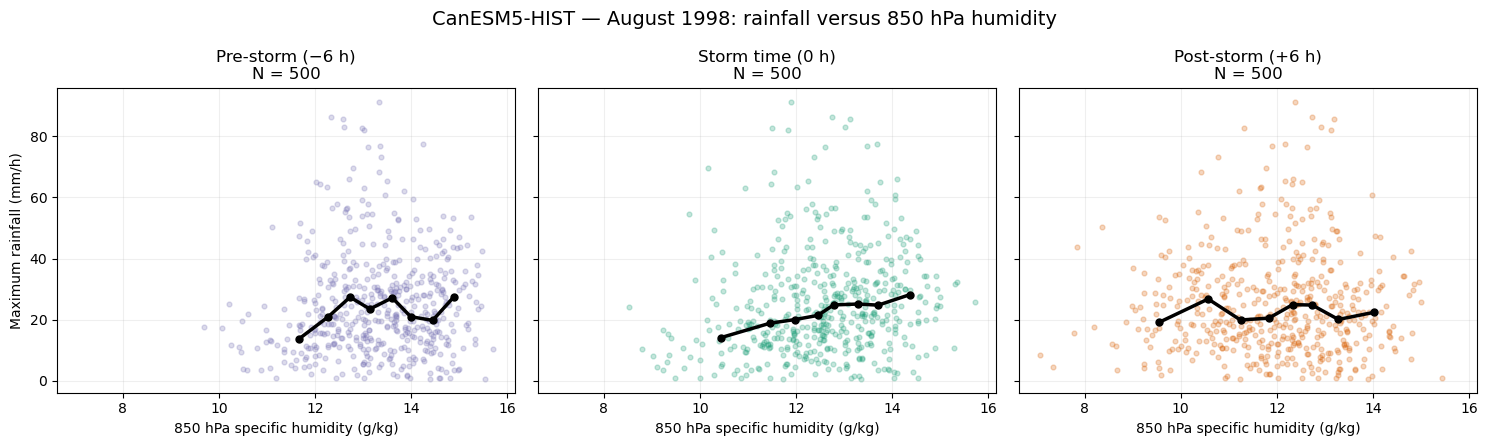

In [31]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# SETTINGS
# ============================================================

ROOT = Path("/gws/ssde/j25b/cocoon/MCS_5000km2_tables_v3")

RUN = "CanESM5-HIST"
YEAR = 1998
MONTH = 8
N_STORMS = 500

# ============================================================
# LOAD STORM BASE TABLE
# ============================================================

storm_file = (
    ROOT / "CP4_base_tables_tir-prcp" / RUN /
    f"year_{YEAR}" / f"month_{MONTH:02d}.parquet"
)

storms = pd.read_parquet(
    storm_file,
    columns=["storm_id", "precipitation_max", "tmin", "area"]
)

# ============================================================
# LOAD ENVIRONMENTAL SMOKE TEST
# ============================================================

env_file = (
    ROOT / "CP4_storm_timeseries_box07" /
    "_smoke_tests" / f"first_{N_STORMS:04d}_storms" /
    RUN / "q850" /
    f"year_{YEAR}" / f"month_{MONTH:02d}" /
    "part-18utc.parquet"
)

env = pd.read_parquet(env_file)

print("Spatial sampling:", env["spatial_sampling"].unique())
print("Environmental rows:", len(env))
print("Unique storms:", env["storm_id"].nunique())
print("Relative hours:", sorted(env["rel_hour"].unique()))
print("Valid q850 samples:", env["value"].notna().sum())

# ============================================================
# MATCH ENVIRONMENTS WITH STORM PROPERTIES
# ============================================================

df = env.merge(
    storms,
    on="storm_id",
    how="inner",
    validate="many_to_one"
)

# Specific humidity: kg/kg -> g/kg
df["q850_gkg"] = df["value"] * 1000

print(f"\nMatched rows: {len(df):,}")
print(f"Matched storms: {df['storm_id'].nunique():,}")

# ============================================================
# PLOT RAINFALL VS HUMIDITY
# ============================================================

fig, axes = plt.subplots(
    1, 3, figsize=(15, 4.5),
    sharex=True, sharey=True
)

colors = ["#7570b3", "#1b9e77", "#d95f02"]

for ax, rel, color in zip(axes, [-6, 0, 6], colors):

    sub = df.loc[
        (df["rel_hour"] == rel) &
        np.isfinite(df["q850_gkg"]) &
        np.isfinite(df["precipitation_max"])
    ].copy()

    ax.scatter(
        sub["q850_gkg"],
        sub["precipitation_max"],
        s=12, alpha=0.25,
        color=color, rasterized=True
    )

    # Median rainfall in equally populated humidity bins
    if len(sub) >= 50:
        sub["qbin"] = pd.qcut(
            sub["q850_gkg"],
            q=8, duplicates="drop"
        )

        binned = (
            sub.groupby("qbin", observed=True)
            .agg(
                q=("q850_gkg", "median"),
                pmax=("precipitation_max", "median"),
                n=("precipitation_max", "size")
            )
        )

        binned = binned.loc[binned["n"] >= 10]

        ax.plot(
            binned["q"], binned["pmax"],
            "-o", color="black",
            linewidth=2.5, markersize=5,
            label="Binned median"
        )

    label = {
        -6: "Pre-storm (−6 h)",
         0: "Storm time (0 h)",
         6: "Post-storm (+6 h)"
    }[rel]

    ax.set_title(f"{label}\nN = {len(sub)}")
    ax.set_xlabel("850 hPa specific humidity (g/kg)")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Maximum rainfall (mm/h)")

fig.suptitle(
    f"{RUN} — August {YEAR}: rainfall versus 850 hPa humidity",
    fontsize=14
)

plt.tight_layout()
plt.show()
